# Recuperación de información sobre BBC News

Notebook de entrega de la práctica. La lógica vive en `src/*.py`; aquí se importan y ejecutan esos scripts y se muestran las tablas y figuras de `reports/`.

Cada sección corresponde a una etapa del pipeline que ya pasó la validación de calidad (`reports/validacion/<etapa>.md`). Para reproducir el entorno, ver `ENTORNO.md`.

## 0. Setup

Estructura de carpetas, dependencias (`requirements.txt`) y entorno `bbc-ir` (Python 3.11). La celda siguiente ubica el notebook en la raíz del repositorio, agrega `src/` a la ruta de importación y comprueba las librerías.

In [1]:
import os, sys, json
from pathlib import Path
from importlib.metadata import version

# Raíz del repositorio: la carpeta que contiene src/ y estado/
RAIZ = Path.cwd()
while not (RAIZ / 'src').is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
if str(RAIZ / 'src') not in sys.path:
    sys.path.insert(0, str(RAIZ / 'src'))

import pandas as pd
import spacy
from IPython.display import Image, Markdown, display

spacy.load('en_core_web_sm')  # el corpus está en inglés
pd.set_option('display.max_colwidth', 80)

libs = ['pandas', 'numpy', 'scikit-learn', 'scipy', 'rank-bm25', 'gensim', 'spacy', 'nltk',
        'matplotlib', 'wordcloud', 'python-pptx', 'pyyaml', 'joblib']
print('Python', sys.version.split()[0])
pd.DataFrame({'libreria': libs, 'version': [version(l) for l in libs]})

Python 3.11.17


,libreria,version
0,pandas,3.0.6
1,numpy,2.4.6
2,scikit-learn,1.9.1
3,scipy,1.17.1
4,rank-bm25,0.2.2
5,gensim,4.4.0
6,spacy,3.8.16
7,nltk,3.10.3
8,matplotlib,3.11.2
9,wordcloud,1.9.6


In [2]:
# Estado del pipeline (fuente de verdad: estado/progreso.json)
progreso = json.load(open('estado/progreso.json'))
pd.DataFrame(progreso['etapas']).T[['estado', 'intentos', 'commit']]

,estado,intentos,commit
setup,PASS,0,679174d
descarga,PASS,0,32ea3e5
eda_raw,PASS,0,6eb45bf
limpieza,PASS,0,59db66d
eda_corpus,PASS,0,d800aff
indices,PASS,0,d47162a
evaluacion,PASS,0,c5638bf
presentacion,PASS,0,da38933


## 1. Descarga

`src/descarga.py` obtiene `data/raw/bbc-text.csv` (si ya existe no lo vuelve a bajar), calcula su SHA-256 y verifica 2,225 filas y las 5 categorías esperadas.

In [3]:
import descarga

df_raw = descarga.main()

ya existe: /Users/mikitl/Documents/FES/Ciencia de Datos/Clases/míneriaTextos/BBC-News-Classification/data/raw/bbc-text.csv (5,059,719 bytes)
SHA-256: e7652d6aa0fa92b2d02c6a992ebda82281041f83e7c2a92ae6e9c1c444981a8d
shape: (2225, 2)
conteo por categoría:
category
sport            511
business         510
politics         417
tech             401
entertainment    386
nulos por columna:
category    0
text        0
verificación OK


In [4]:
conteo = df_raw['category'].value_counts().rename_axis('categoria').reset_index(name='documentos')
conteo['porcentaje'] = (conteo['documentos'] / len(df_raw) * 100).map('{:.2f}%'.format)
print(f'Filas: {len(df_raw):,} | SHA-256:', open(descarga.RUTA_SHA).read().split()[0])
conteo

Filas: 2,225 | SHA-256: e7652d6aa0fa92b2d02c6a992ebda82281041f83e7c2a92ae6e9c1c444981a8d


,categoria,documentos,porcentaje
0,sport,511,22.97%
1,business,510,22.92%
2,politics,417,18.74%
3,tech,401,18.02%
4,entertainment,386,17.35%


In [5]:
display(Markdown(open('reports/descarga.md', encoding='utf-8').read()))

# Reporte de descarga

- **Fecha:** 2026-10-11
- **URL oficial:** https://raw.githubusercontent.com/mdsohaib/BBC-News-Classification/master/bbc-text.csv (repositorio: https://github.com/mdsohaib/BBC-News-Classification, rama `master`)
- **Origen usado:** copia local ya existente en `data/raw/bbc-text.csv` (mismo archivo del repositorio oficial). No se descargó de internet; el script tomó la rama `ya existe`.
- **Tamaño:** 5,059,719 bytes
- **SHA-256:** `e7652d6aa0fa92b2d02c6a992ebda82281041f83e7c2a92ae6e9c1c444981a8d` (guardado en `data/raw/bbc-text.sha256`)
- **Columnas:** `category`, `text`
- **Filas:** 2,225 (coincide con lo esperado)
- **Nulos:** 0 en `category`, 0 en `text`
- **Duplicados:** 99 textos duplicados (se eliminan en la etapa `limpieza`, no aquí)

## Conteo por categoría

| Categoría | Documentos |
|---|---:|
| sport | 511 |
| business | 510 |
| politics | 417 |
| tech | 401 |
| entertainment | 386 |
| **Total** | **2,225** |

## Verificación

Filas = 2,225 y las 5 categorías esperadas con los conteos esperados: **OK**. El texto no fue limpiado ni modificado.


## 2. EDA del corpus crudo

`src/eda.py --modo raw` describe el CSV original antes de limpiarlo: categorías, nulos, duplicados, longitudes y caracteres no alfabéticos. El reporte completo está en `reports/eda_raw.md`.

In [6]:
import matplotlib
matplotlib.use('Agg')  # las figuras se guardan en reports/figuras y se muestran desde ahí
import eda

m_raw = eda.eda_raw()

In [7]:
cats = pd.DataFrame({
    'documentos': m_raw['conteo_categorias'],
    'porcentaje': m_raw['porcentaje_categorias'],
    'duplicados': m_raw['duplicados_por_categoria'],
    'tras_deduplicar': m_raw['conteo_categorias_tras_deduplicar'],
})
cats['porcentaje'] = cats['porcentaje'].map('{:.2f}%'.format)
print(f"Documentos: {m_raw['n_docs']:,} | duplicados exactos: {m_raw['n_duplicados']:,} | tras deduplicar: {m_raw['n_docs_tras_deduplicar']:,}")
cats

Documentos: 2,225 | duplicados exactos: 99 | tras deduplicar: 2,126


,documentos,porcentaje,duplicados,tras_deduplicar
business,510,22.92%,7,503
entertainment,386,17.35%,17,369
politics,417,18.74%,14,403
sport,511,22.97%,7,504
tech,401,18.02%,54,347


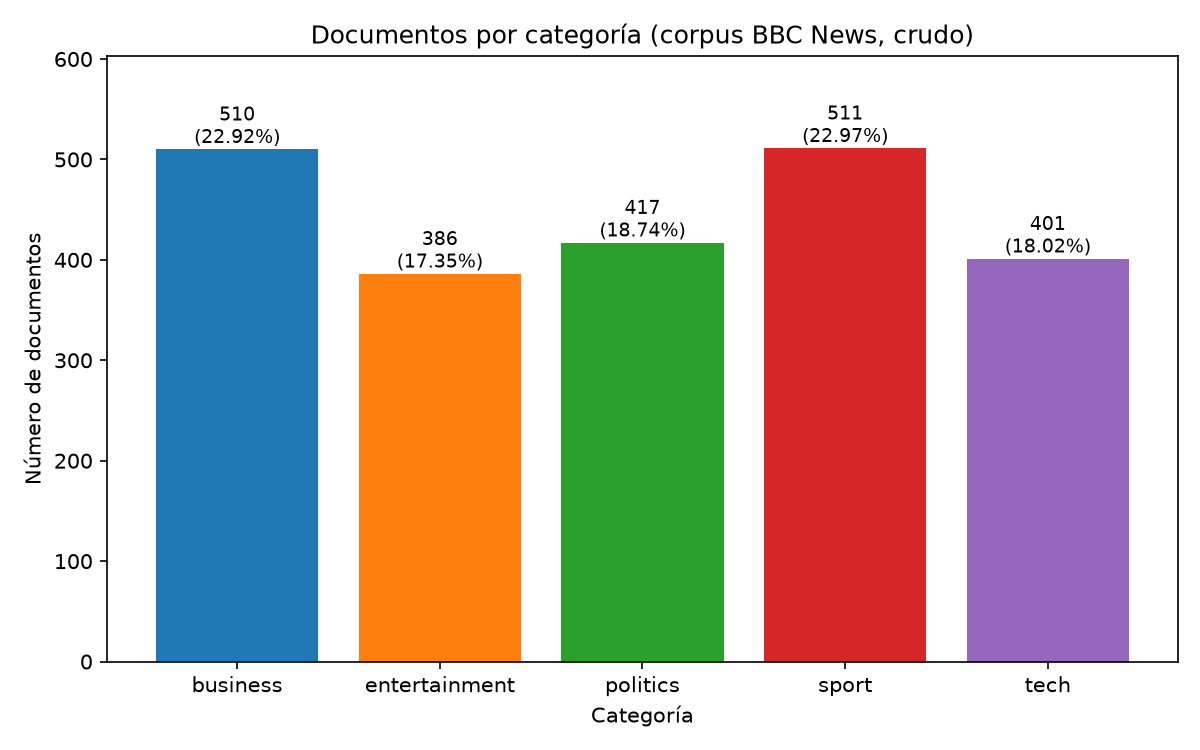

In [8]:
display(Image('reports/figuras/raw_categorias.png', width=700))

In [9]:
# Longitud en palabras, global y por categoría
pd.DataFrame(m_raw['longitud_palabras']).T.round(2)

,media,mediana,min,max,p25,p75
global,390.30,337.0,90.0,4492.0,250.00,479.00
business,334.19,303.0,142.0,912.0,236.00,395.75
entertainment,337.68,267.0,144.0,3570.0,228.25,367.75
politics,461.19,449.0,90.0,4492.0,320.00,536.00
sport,336.32,296.0,116.0,1671.0,208.00,415.50
tech,507.36,450.0,165.0,3007.0,340.00,633.00


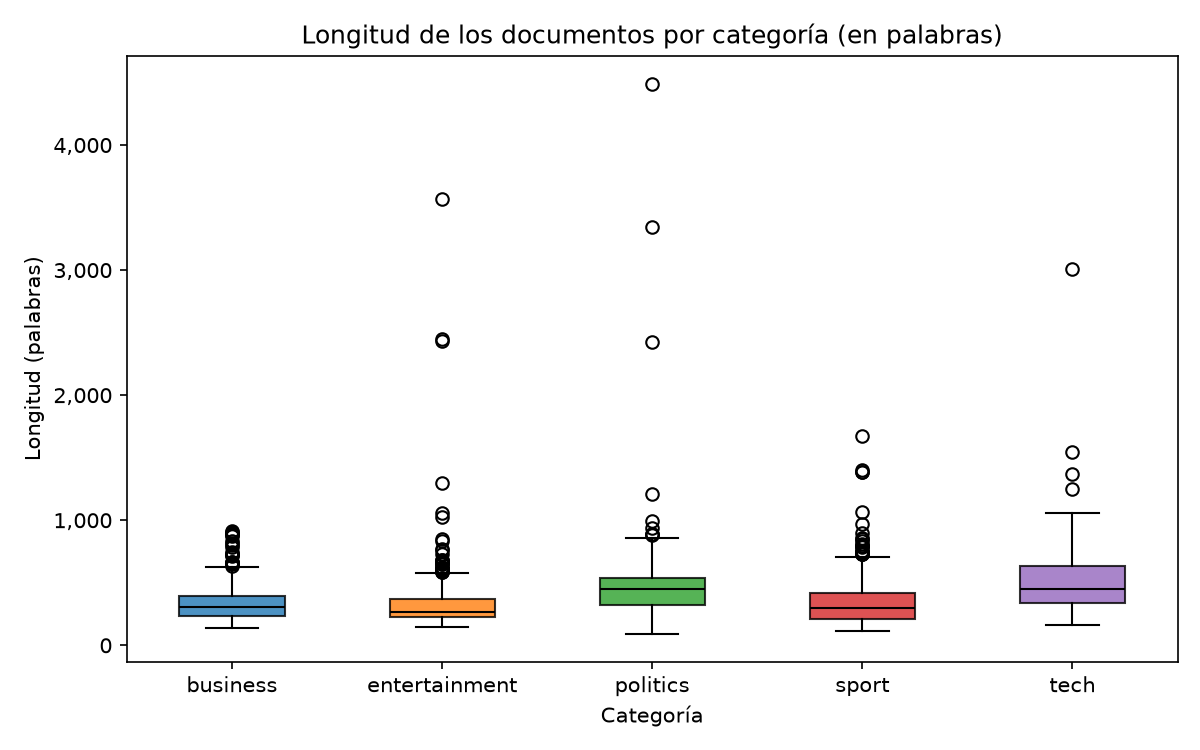

In [10]:
display(Image('reports/figuras/raw_longitudes.png', width=700))

In [11]:
simbolos = pd.Series({'dígitos': m_raw['pct_docs_con_digitos'], **m_raw['pct_docs_con_simbolo']}, name='% de documentos')
simbolos.map('{:.2f}%'.format).to_frame()

,% de documentos
dígitos,95.10%
£,29.08%
$,21.48%
%,28.31%
-,94.56%


**Hallazgos para la limpieza.** Hay 99 textos duplicados (54 de ellos en `tech`), que se eliminan conservando la primera aparición. Casi todos los documentos contienen dígitos y guiones; la etapa de limpieza los elimina y deja solo letras. El texto ya viene en minúsculas y sin acentos.

## 3. Limpieza, normalización y tokenización

`src/preprocesamiento.py` define **una sola función**, `preprocesar`, que se usa igual para el corpus, para noticias nuevas y para las consultas. `src/limpieza.py` la aplica al corpus: quita duplicados, descarta documentos con menos de 20 tokens y guarda `data/processed/corpus_clean.csv`.

In [12]:
from preprocesamiento import normalizar, tokenizar, preprocesar, STOPWORDS_EXTRA
import limpieza

# Cambia a True para regenerar el corpus limpio desde el CSV crudo (~35 s); el resultado es idéntico.
REEJECUTAR_LIMPIEZA = False
if REEJECUTAR_LIMPIEZA:
    limpieza.main()

m_limp = json.load(open('reports/limpieza.json'))
print(f"Documentos: {m_limp['n_antes']:,} -> {m_limp['n_despues']:,} | duplicados: {m_limp['duplicados']:,} | "
      f"descartados por cortos: {m_limp['descartados_cortos']:,} | tokens promedio: {m_limp['tokens_promedio']['antes']:,.2f} -> {m_limp['tokens_promedio']['despues']:,.2f}")
print('Stopwords propias:', STOPWORDS_EXTRA)

Documentos: 2,225 -> 2,126 | duplicados: 99 | descartados por cortos: 0 | tokens promedio: 390.45 -> 181.42
Stopwords propias: ['said', 'mr', 'mrs', 'ms', 'also', 'would', 'could', 'year', 'years', 'new', 'one', 'two']


In [13]:
# La misma función sirve para una consulta o un documento nuevo
ejemplo = 'The Markets were FALLING in 2005, said Mr Brown: shares lost £3bn!'
print('normalizar :', normalizar(ejemplo))
print('tokenizar  :', tokenizar(normalizar(ejemplo)))
print('lemma      :', preprocesar(ejemplo, modo='lemma'))
print('stem       :', preprocesar(ejemplo, modo='stem'))

normalizar : the markets were falling in said mr brown shares lost bn
tokenizar  : ['markets', 'falling', 'brown', 'shares', 'lost']
lemma      : ['market', 'fall', 'brown', 'share', 'lose']
stem       : ['market', 'fall', 'brown', 'share', 'lost']


In [14]:
corpus = pd.read_csv('data/processed/corpus_clean.csv')
print(f'{len(corpus):,} documentos, columnas: {list(corpus.columns)}')
corpus[['doc_id', 'category', 'titulo', 'tokens_lemma', 'n_tokens']].head()

2,126 documentos, columnas: ['doc_id', 'category', 'titulo', 'text_original', 'text_norm', 'tokens_lemma', 'tokens_stem', 'n_tokens']


,doc_id,category,titulo,tokens_lemma,n_tokens
0,doc_0000,tech,tv future in the hands of viewers with,future hand viewer home theatre system plasma highdefinition tvs digital vid...,329
1,doc_0001,business,worldcom boss left books alone former worldcom boss,worldcom boss leave books worldcom boss bernie ebber accuse oversee fraud ac...,151
2,doc_0002,sport,tigers wary of farrell gamble leicester say they,tiger wary farrell gamble leicester rush bid andy farrell great britain rugb...,98
3,doc_0003,sport,yeading face newcastle in fa cup premiership side,yeade face newcastle cup premiership newcastle united face trip ryman premie...,217
4,doc_0004,entertainment,ocean s twelve raids box office ocean s,ocean raids box office ocean crime caper sequel star george clooney brad pit...,141


In [15]:
resumen = corpus.groupby('category')['n_tokens'].agg(documentos='count', media='mean', mediana='median', minimo='min', maximo='max').round(2)
resumen

,documentos,media,mediana,minimo,maximo
category,,,,,
business,503,161.40,148.0,62,440
entertainment,369,161.44,131.0,69,1489
politics,403,210.15,208.0,40,1838
sport,504,153.02,128.5,51,779
tech,347,239.55,218.0,81,1213


**Decisiones.** Se eliminan dígitos y todo lo que no sea letra (los guiones se borran sin dejar espacio: `high-definition` queda como `highdefinition`), se quitan las stopwords de spaCy más la lista propia, y las etapas siguientes usan `tokens_lemma`. El detalle y los ejemplos están en `reports/limpieza.md`.

## 4. EDA del corpus limpio

`src/eda.py --modo corpus` analiza `tokens_lemma`: tamaño del vocabulario, ley de Zipf, ley de Heaps, nubes de palabras y la comparación entre lematizar y stemizar. El reporte completo está en `reports/eda_corpus.md`.

In [16]:
m_corpus = eda.eda_corpus()

pd.Series({
    'Tokens (N)': f"{m_corpus['N']:,}",
    'Vocabulario (V)': f"{m_corpus['V']:,}",
    'Hapax legomena': f"{m_corpus['hapax']:,} ({m_corpus['hapax_pct_vocabulario']:.2f}% del vocabulario)",
    'Vocabulario con stem': f"{m_corpus['V_stem']:,} ({m_corpus['reduccion_vocabulario_stem_vs_lemma_pct']:.2f}% menos que con lema)",
}, name='valor').to_frame()

,valor
Tokens (N),"385,689"
Vocabulario (V),"24,971"
Hapax legomena,"9,980 (39.97% del vocabulario)"
Vocabulario con stem,"21,127 (15.39% menos que con lema)"


In [17]:
top = pd.read_csv('reports/vocabulario_top.csv')
top15 = top[top['rango'] <= 15].pivot(index='rango', columns='ambito', values='termino')
top15[['global', 'business', 'entertainment', 'politics', 'sport', 'tech']]

ambito,global,business,entertainment,politics,sport,tech
rango,,,,,,
1,people,company,film,labour,win,people
2,win,firm,good,government,game,game
3,good,market,award,party,play,technology
4,game,rise,music,people,player,mobile
5,time,sale,star,election,england,phone
6,world,bank,win,minister,good,service
7,government,price,include,blair,world,user
8,come,share,actor,plan,time,use
9,play,economy,band,tory,come,computer


### Ley de Zipf

Ajuste `log f = log C − s·log r` sobre los rangos 1 a 1,000.

s = 0.6088 | R² = 0.9469


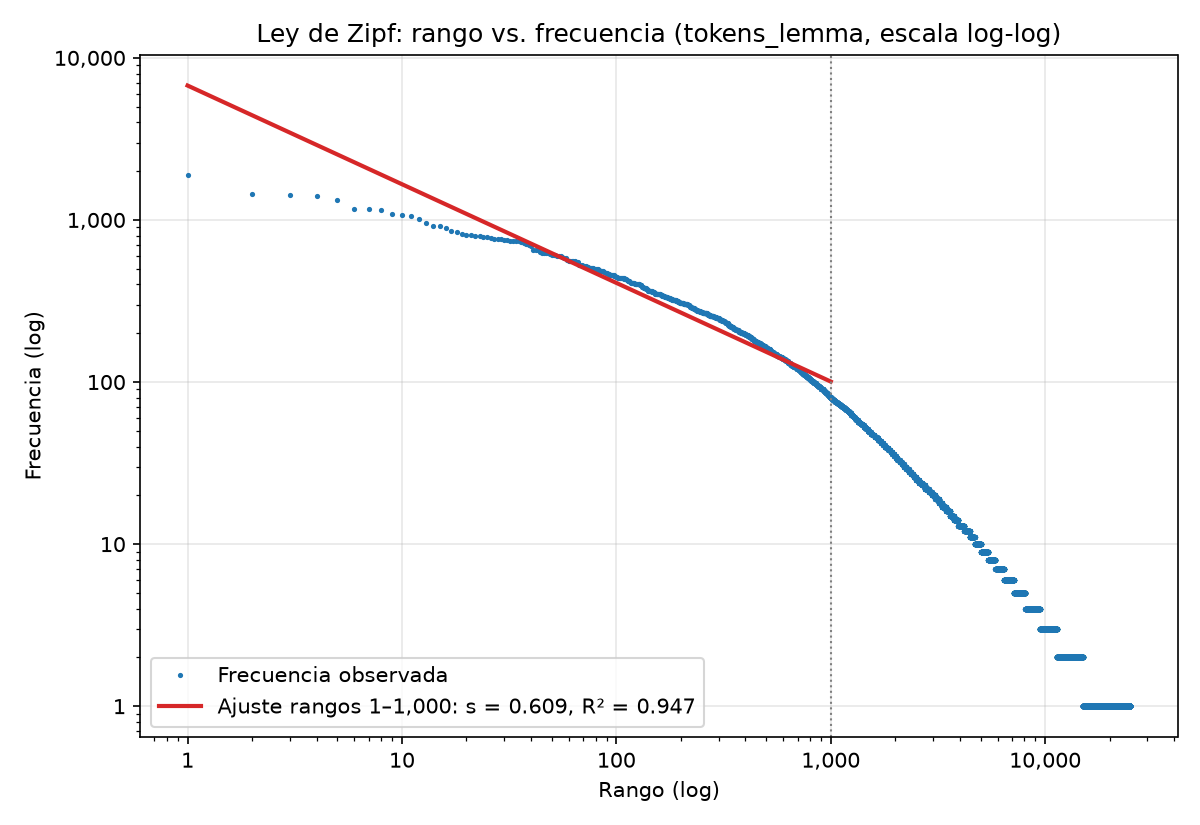

In [18]:
print(f"s = {m_corpus['zipf_s']:.4f} | R² = {m_corpus['zipf_r2']:.4f}")
display(Image('reports/figuras/zipf.png', width=700))

El exponente queda por debajo del valor clásico (cercano a 1) porque al quitar las stopwords desaparece la cabeza de la distribución: las palabras más frecuentes que quedan tienen frecuencias parecidas entre sí. La celda siguiente lo comprueba repitiendo el mismo ajuste sobre el texto normalizado, que todavía conserva las stopwords.

In [19]:
import numpy as np
from collections import Counter

def ajuste_zipf(textos, r_max=1000):
    frec = np.array(sorted(Counter(t for s in textos for t in s.split()).values(), reverse=True)[:r_max], dtype=float)
    x, y = np.log(np.arange(1, len(frec) + 1)), np.log(frec)
    pendiente, ordenada = np.polyfit(x, y, 1)
    r2 = 1 - ((y - (ordenada + pendiente * x)) ** 2).sum() / ((y - y.mean()) ** 2).sum()
    return -pendiente, r2

pd.DataFrame({'con stopwords (text_norm)': ajuste_zipf(corpus['text_norm']),
              'sin stopwords (tokens_lemma)': ajuste_zipf(corpus['tokens_lemma'])}, index=['s', 'R²']).round(4)

,con stopwords (text_norm),sin stopwords (tokens_lemma)
s,0.9165,0.6088
R²,0.9960,0.9469


### Ley de Heaps

Ajuste `V = K·n^β` recorriendo los documentos en orden aleatorio (semilla 42) y registrando cada 5,000 tokens.

K = 25.25 | β = 0.5387 | R² = 0.9976


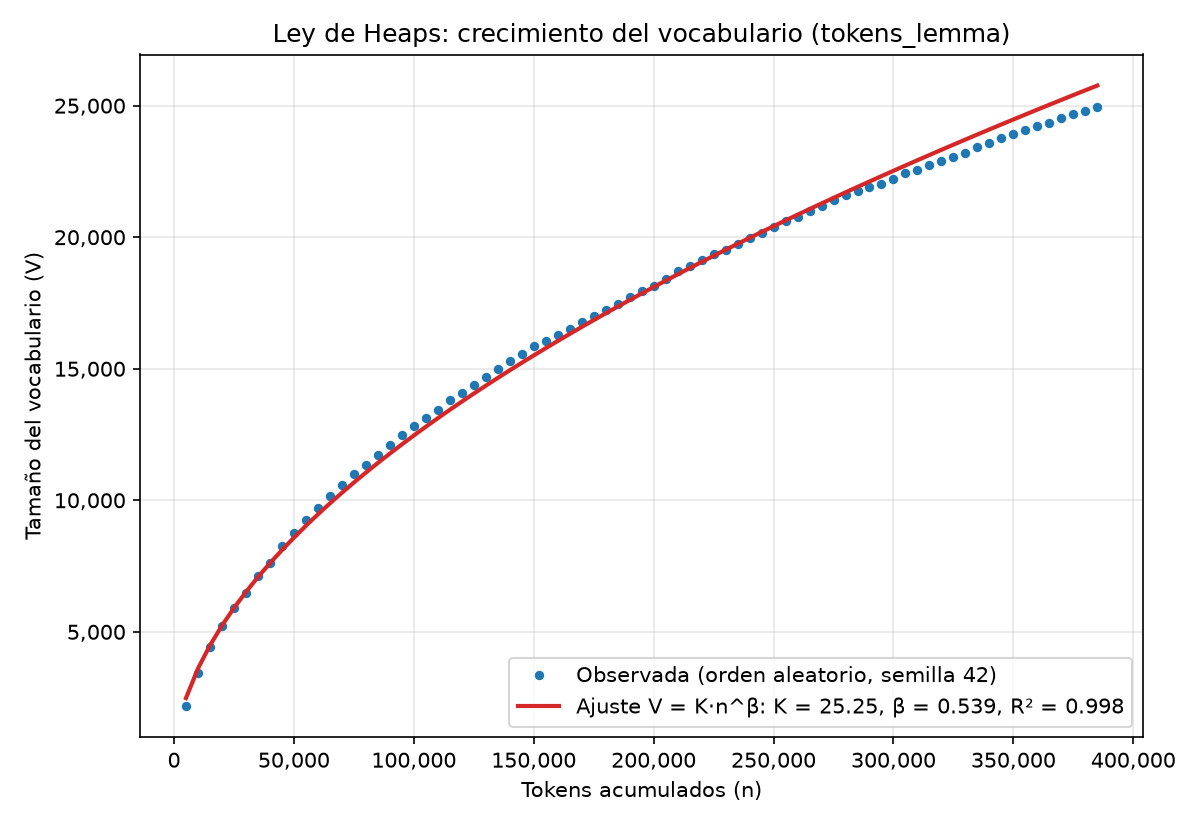

In [20]:
print(f"K = {m_corpus['heaps_K']:.2f} | β = {m_corpus['heaps_beta']:.4f} | R² = {m_corpus['heaps_r2']:.4f}")
display(Image('reports/figuras/heaps.png', width=700))

### Nubes de palabras

**global**

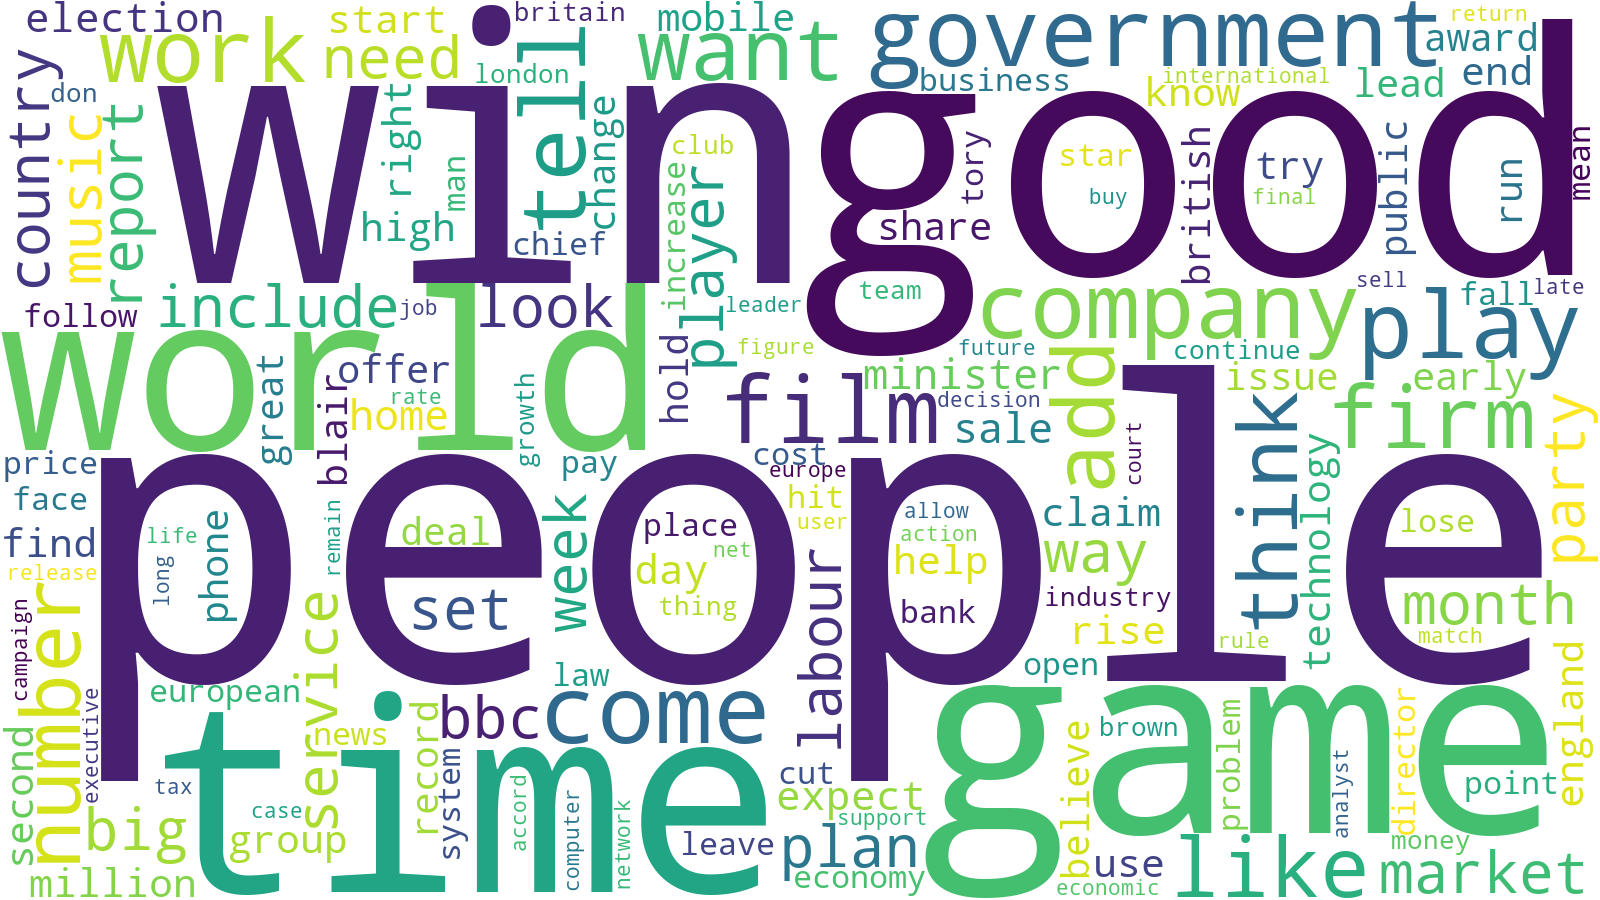

**business**

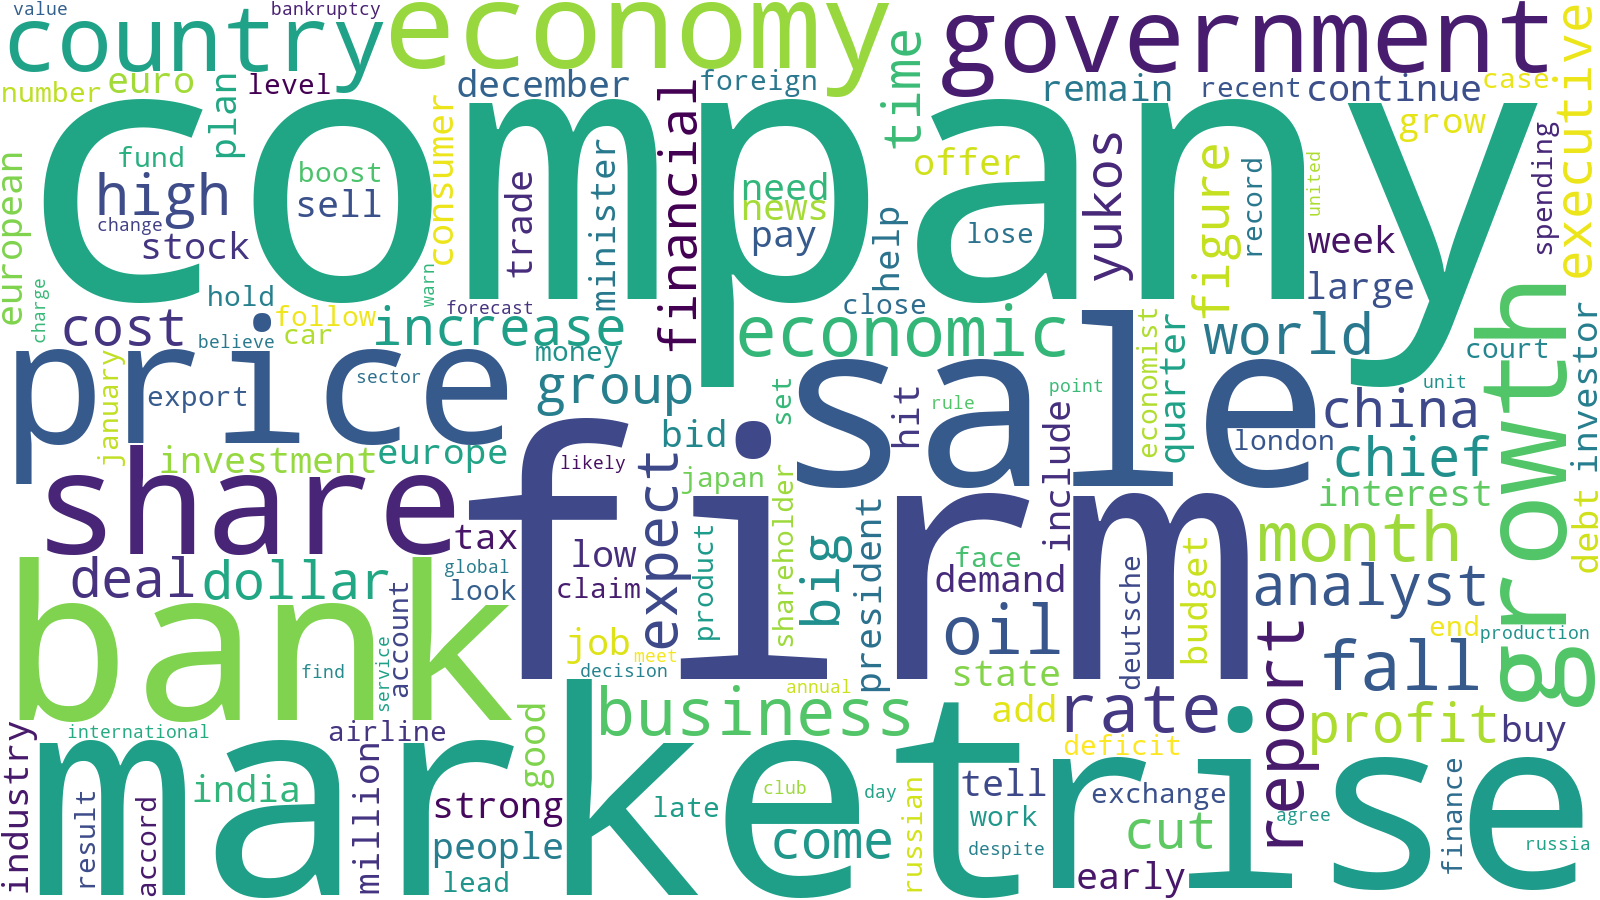

**entertainment**

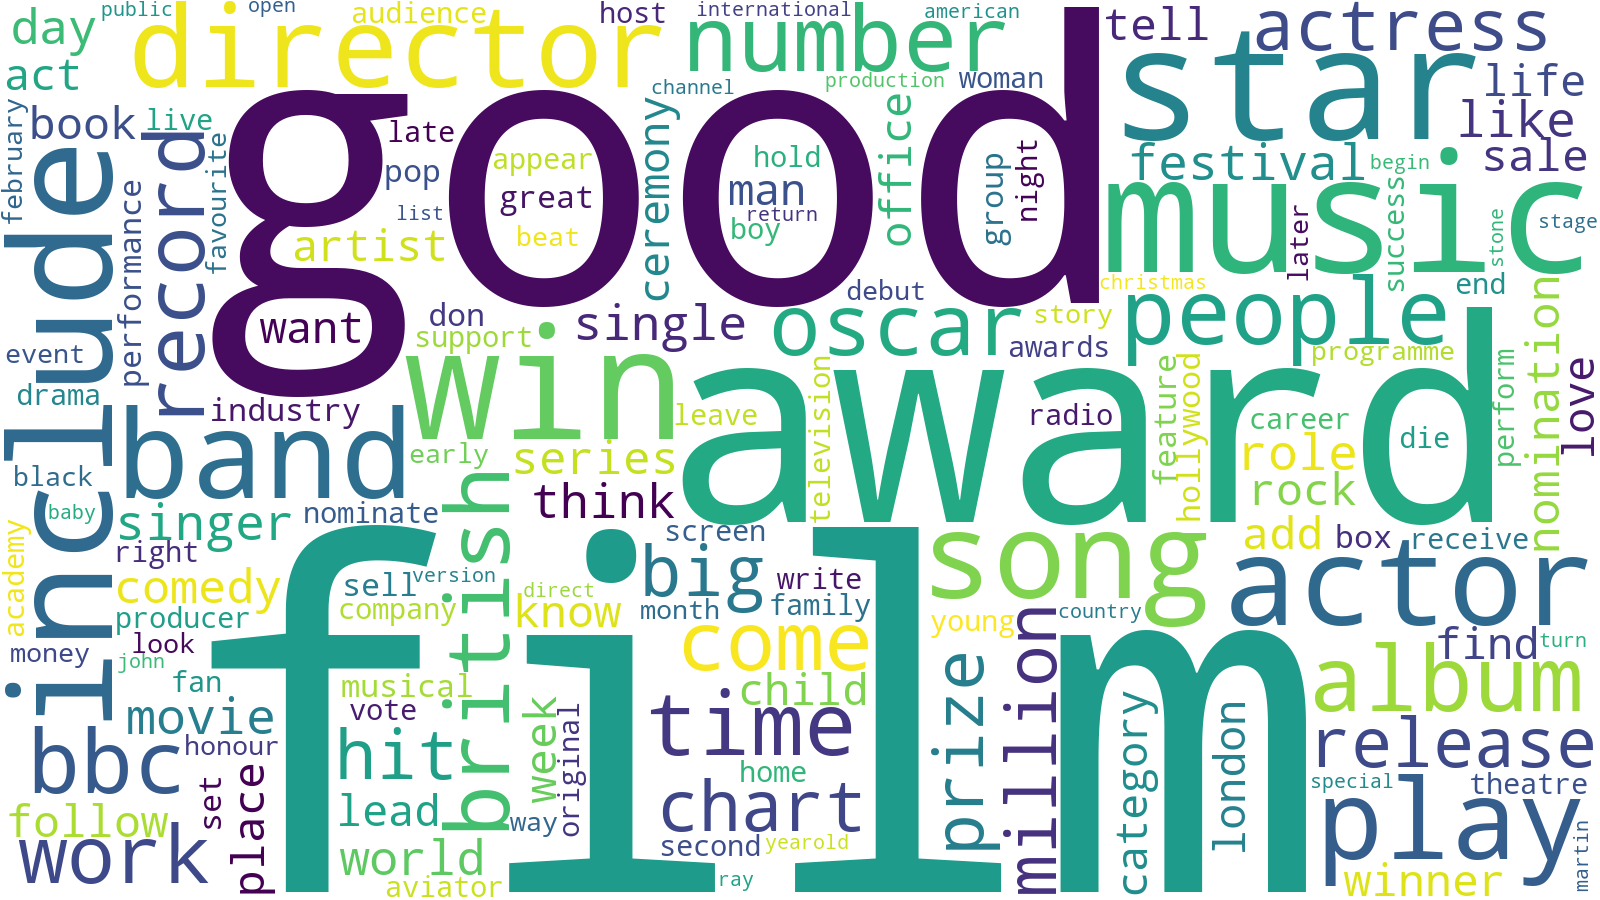

**politics**

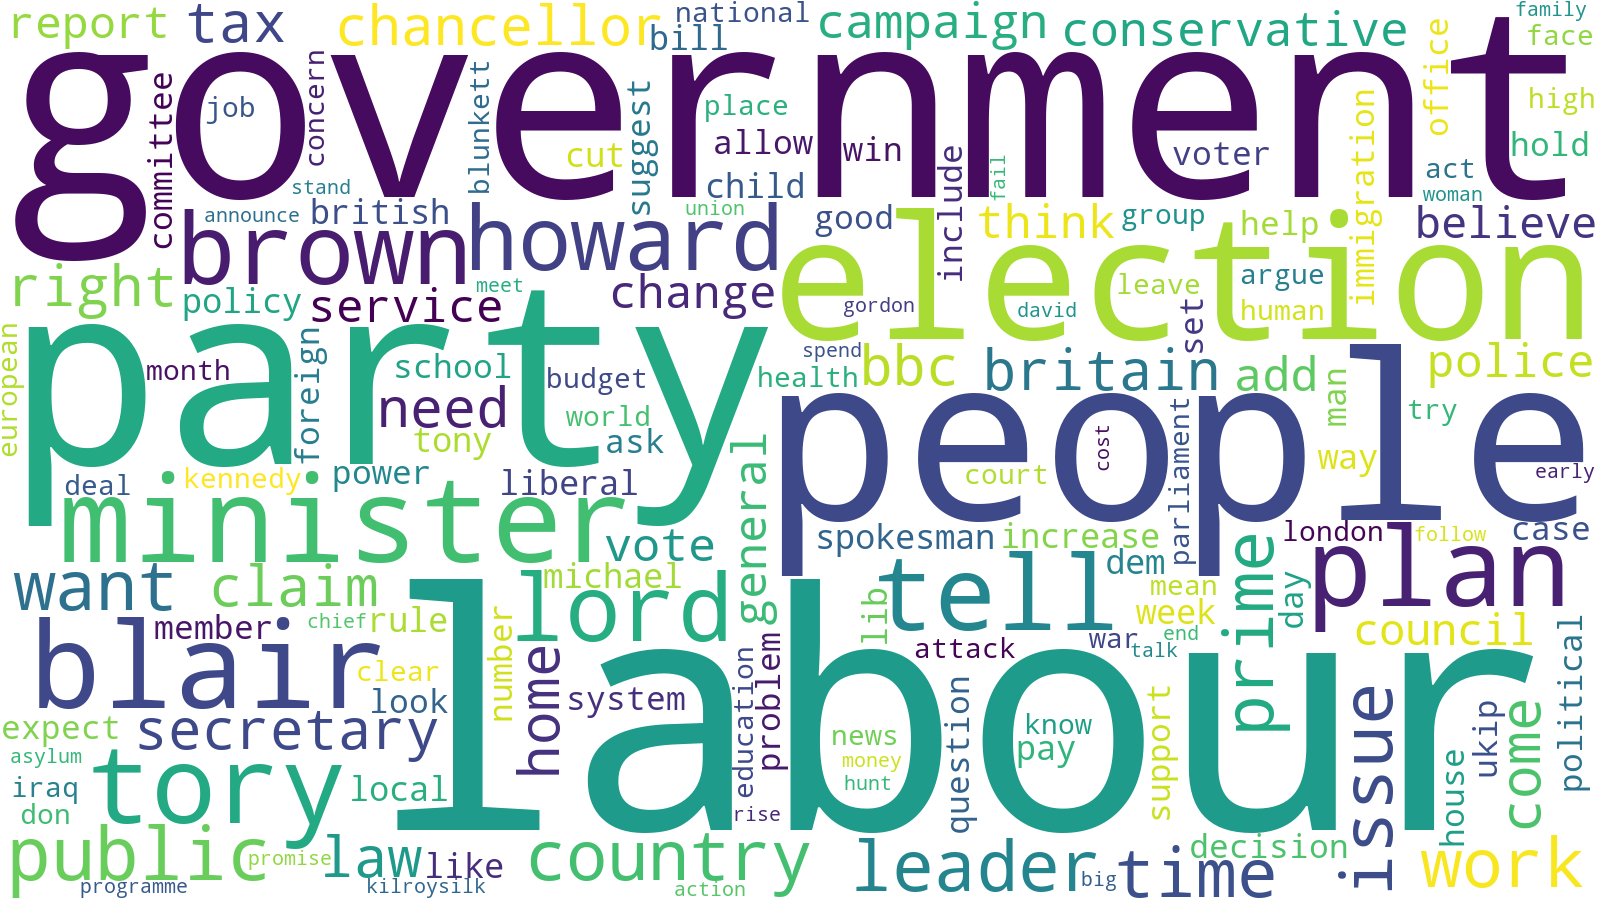

**sport**

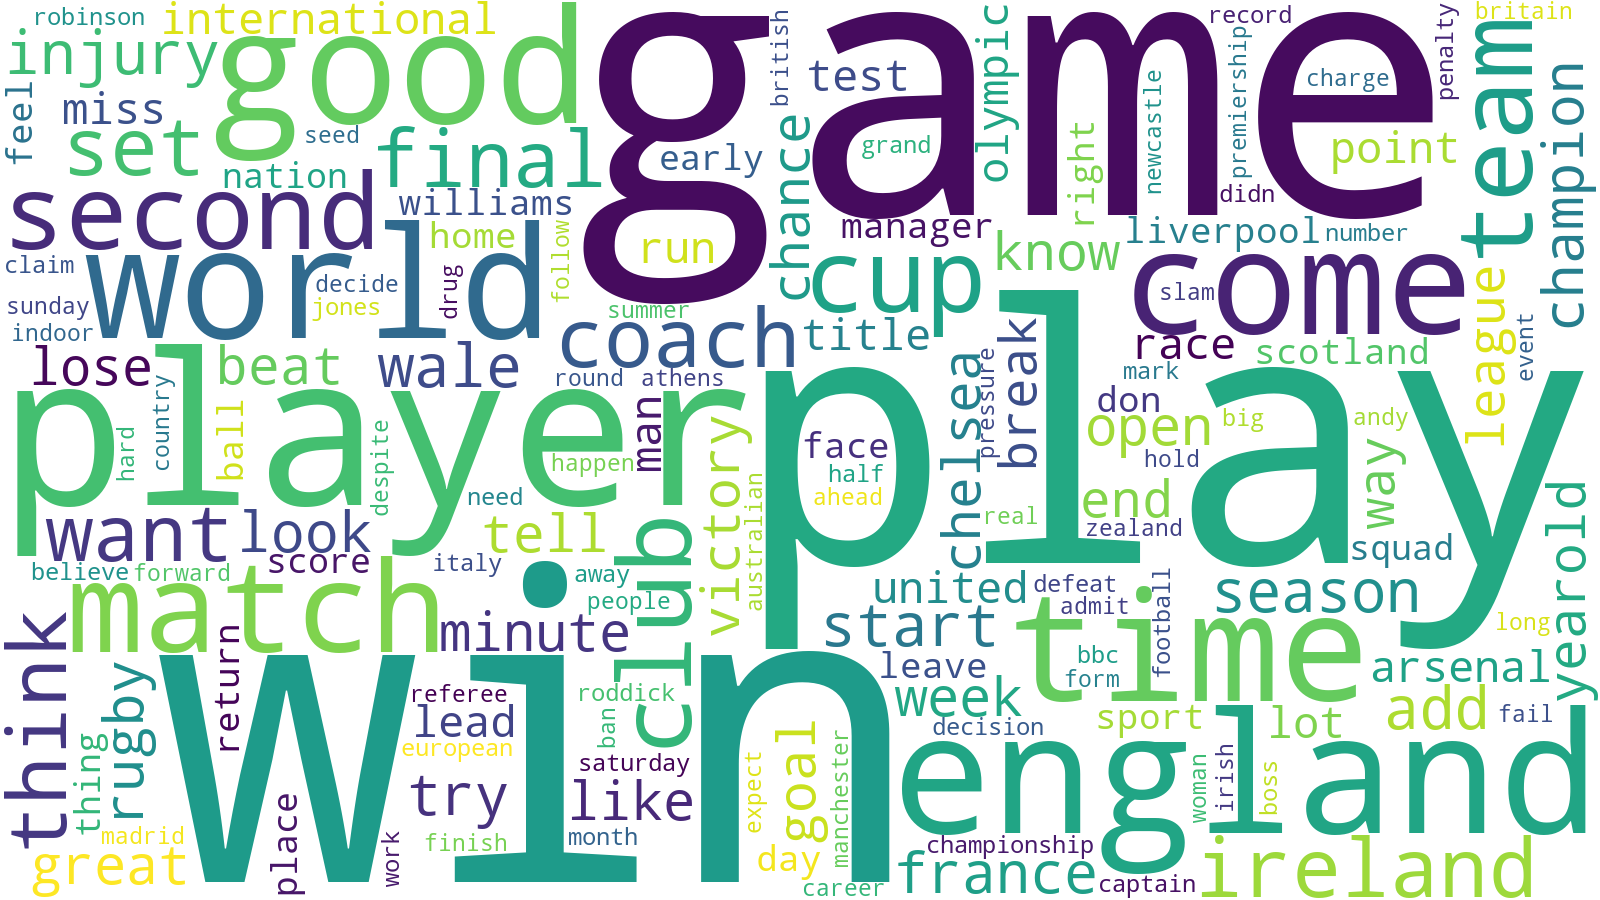

**tech**

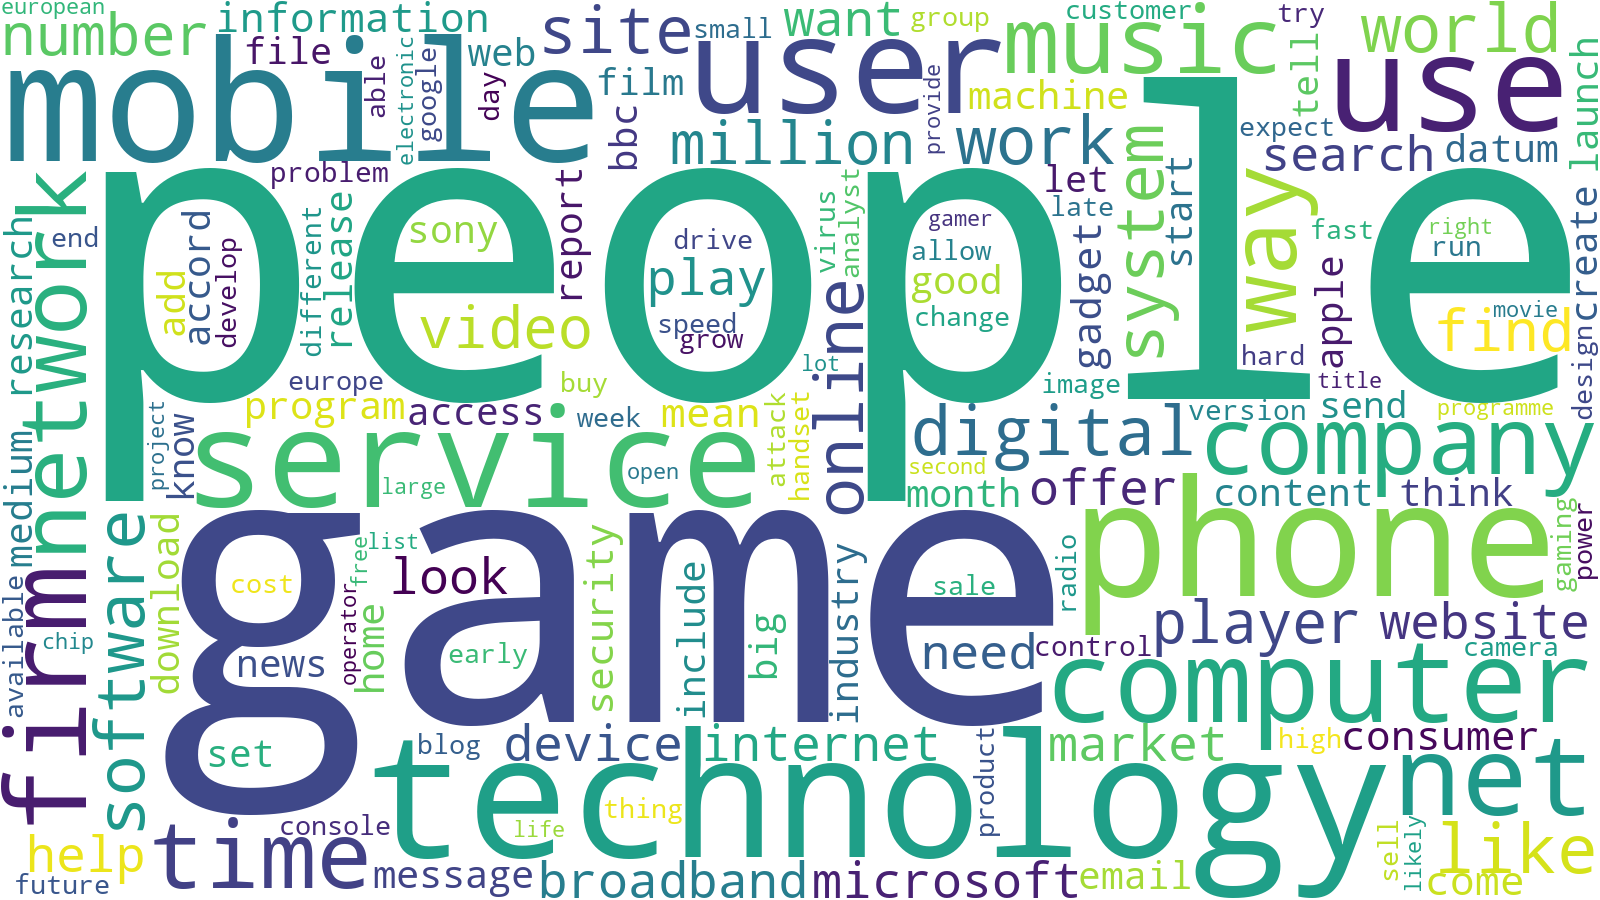

In [21]:
for nombre in ['global', 'business', 'entertainment', 'politics', 'sport', 'tech']:
    display(Markdown(f'**{nombre}**'))
    display(Image(f'reports/figuras/wordcloud_{nombre}.png', width=600))

**Conclusiones para la indexación.** Cerca del 40% del vocabulario aparece una sola vez, así que filtrar términos con `min_df=2` reduce mucho las matrices sin perder señal. El vocabulario sigue creciendo con el corpus (β ≈ 0.54), por lo que la ingesta de noticias nuevas debe reconstruir los índices. Cada categoría tiene un vocabulario propio reconocible, lo que justifica usar la categoría como criterio de relevancia en la evaluación.

## 5. Índices, búsqueda e ingesta

`src/indices.py` construye seis representaciones del corpus sobre `tokens_lemma`: CountVectorizer, TF-IDF, BM25 y SVD/LSA, más Word2Vec y LDA como extras. `src/buscar.py` expone `buscar(query, metodo, k)` y `src/ingesta.py` agrega noticias nuevas y reconstruye los índices.

In [22]:
import indices, buscar as buscador
from buscar import buscar

# Los modelos binarios no se versionan: si faltan (p. ej. en otra computadora) se construyen aquí (~40 s).
obligatorios = ['count.pkl', 'tfidf.pkl', 'bm25.pkl', 'svd.pkl', 'lda.pkl', 'w2v.model', 'w2v_docs.npy', 'doc_index.csv']
if not all((indices.MODELOS / f).exists() for f in obligatorios):
    indices.construir_indices()
    buscador.recargar()

m_idx = json.load(open('reports/indices.json'))
tabla_idx = pd.DataFrame(m_idx['metodos']).T[['dimensiones', 'vocabulario', 'densidad_pct', 'tiempo_s']]
tabla_idx['dimensiones'] = tabla_idx['dimensiones'].map(lambda d: f'{d[0]:,} × {d[1]:,}')
tabla_idx['vocabulario'] = tabla_idx['vocabulario'].map('{:,}'.format)
tabla_idx['densidad_pct'] = tabla_idx['densidad_pct'].map('{:.2f}%'.format)
tabla_idx

,dimensiones,vocabulario,densidad_pct,tiempo_s
count,"2,126 × 13,350","13,350",0.89%,0.11
tfidf,"2,126 × 13,350","13,350",0.89%,0.1
bm25,"2,126 × 24,971","24,971",0.50%,0.08
svd,"2,126 × 200","13,350",100.00%,0.61
w2v,"2,126 × 100","14,991",100.00%,29.41
lda,"2,126 × 10","13,350",100.00%,6.93


SVD: 33.03% de varianza explicada con 200 componentes


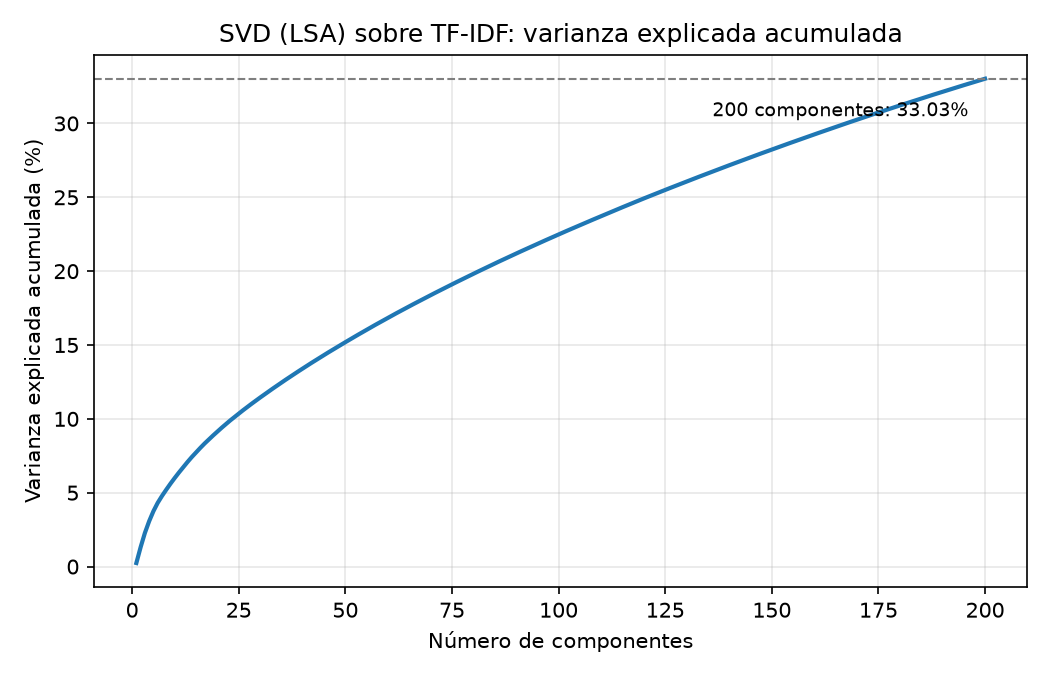

In [23]:
print(f"SVD: {m_idx['metodos']['svd']['varianza_explicada_acumulada_pct']:.2f}% de varianza explicada con 200 componentes")
display(Image('reports/figuras/svd_varianza.png', width=700))

In [24]:
# Tópicos de LDA (10 palabras principales y etiqueta asignada)
pd.read_csv('reports/lda_topicos.csv')

,topico,etiqueta,palabras
0,0,Economía y precios,"rise, market, sale, growth, price, economy, rate, fall, month, economic"
1,1,Música,"music, band, song, album, number, chart, record, single, artist, rock"
2,2,Leyes y tribunales,"law, government, case, court, tell, lord, rule, right, police, company"
3,3,Política británica y elecciones,"labour, party, election, people, blair, government, minister, tory, brown, plan"
4,4,Rugby y fútbol: partidos,"win, minute, ireland, second, ball, try, run, game, penalty, italy"
5,5,"Yukos, deuda y Rusia (mixto)","open, bank, yukos, world, set, win, country, russian, play, debt"
6,6,Tecnología móvil y usuarios,"people, game, technology, mobile, phone, service, use, user, computer, network"
7,7,Fútbol: jugadores y clubes,"game, play, win, england, player, club, time, good, team, think"
8,8,Cine y premios,"film, good, award, star, win, include, actor, director, oscar, prize"
9,9,"Empresas, ofertas y fusiones","company, china, firm, share, deal, offer, india, bid, market, airline"


### Pipeline de consulta

La consulta pasa por el mismo `preprocesar` que el corpus, se vectoriza con el modelo del índice (solo `transform`) y se ordena por similitud coseno, o por puntaje BM25.

In [25]:
buscar('oil prices rise', metodo='bm25', k=5)

,rank,doc_id,category,titulo,score
0,1,doc_0674,business,winter freeze keeps oil above $50 oil prices,14.528917
1,2,doc_0800,business,bp surges ahead on high oil price oil,14.039309
2,3,doc_0012,business,crude oil prices back above $50 cold weather,13.296888
3,4,doc_0720,business,oil prices fall back from highs oil prices,13.017120
4,5,doc_0095,business,oil rebounds from weather effect oil prices recovered,12.944389


In [26]:
# Las tres consultas de prueba con los seis métodos: categorías del top-5
consultas_prueba = {'stock market shares fall': 'business', 'election labour party vote': 'politics', 'mobile phone software': 'tech'}
filas = []
for q, esperada in consultas_prueba.items():
    for metodo in buscador.METODOS:
        r = buscar(q, metodo, k=5)
        filas.append({'consulta': q, 'metodo': metodo, 'esperada': esperada,
                      'aciertos_top5': int((r['category'] == esperada).sum()), 'primer_resultado': r['titulo'].iloc[0]})
pd.DataFrame(filas)

,consulta,metodo,esperada,aciertos_top5,primer_resultado
0,stock market shares fall,count,business,5,google shares fall as staff sell shares in
1,stock market shares fall,tfidf,business,5,google shares fall as staff sell shares in
2,stock market shares fall,bm25,business,5,google shares fall as staff sell shares in
3,stock market shares fall,svd,business,5,hariri killing hits beirut shares shares in solidere
4,stock market shares fall,w2v,business,5,nasdaq planning $100m share sale the owner of
5,stock market shares fall,lda,business,5,german economy rebounds germany s economy the biggest
6,election labour party vote,count,politics,5,kennedy s cautious optimism charles kennedy is far
7,election labour party vote,tfidf,politics,5,ukip outspent labour on eu poll the uk
8,election labour party vote,bm25,politics,5,lib dems unveil election slogan the liberal democrats
9,election labour party vote,svd,politics,5,ukip outspent labour on eu poll the uk


In [27]:
# Misma consulta, distinto método: los rankings no son idénticos
pd.concat({m: buscar('mobile phone software', m, k=3).set_index('rank')[['category', 'titulo']] for m in ['tfidf', 'bm25', 'svd']}, axis=1)

tfidf                                                         bm25  \
     category                                              titulo category   
rank                                                                         
1        tech      home phones face unclear future the fixed line     tech   
2        tech  friends fear with lost mobiles people are becoming     tech   
3        tech             mobile gig aims to rock 3g forget about     tech   

                                                              svd  \
                                                  titulo category   
rank                                                                
1     friends fear with lost mobiles people are becoming     tech   
2         hotspot users gain free net calls people using     tech   
3             cebit opens to mobile music tune cebit the     tech   

                                                          
                                                  titulo  
rank                                                      
1                 mobiles rack up 20 years of use mobile  
2     friends fear with lost mobiles people are becoming  
3         home phones face unclear future the fixed line

### Ingesta de noticias nuevas

`ingestar(textos, categorias=None)` aplica el mismo preprocesamiento, descarta duplicados exactos y textos de menos de 20 tokens, asigna `doc_id` consecutivos, añade las filas al corpus y reconstruye todos los índices. No se ejecuta aquí porque modifica `data/processed/corpus_clean.csv`; se usa así:

```python
from ingesta import ingestar
nuevos_ids = ingestar(['texto completo de la noticia ...'], categorias=['tech'])
```

o desde la terminal: `python src/ingesta.py --archivo nuevas.csv`.

## 6. Evaluación

El corpus no trae juicios de relevancia, así que se usa la **categoría como criterio**: un documento recuperado es relevante si tiene la misma categoría que la consulta. Es una aproximación: dos noticias de la misma categoría pueden tratar temas distintos.

`src/consultas.py` genera 115 consultas (100 automáticas a partir de títulos, excluyendo el documento de origen de su propio ranking, y 15 manuales) y `src/evaluacion.py` calcula P@5, P@10, MAP@10, nDCG@10, MRR y latencia para los seis métodos.

In [28]:
import consultas as mod_consultas, evaluacion

# guardar=False: se recalcula todo en memoria sin sobrescribir data/ ni reports/
consultas_df = mod_consultas.generar_consultas(guardar=False)
print(f"{len(consultas_df):,} consultas:", consultas_df['tipo'].value_counts().to_dict())
consultas_df.groupby('tipo').head(3)

115 consultas: {'auto': 100, 'manual': 15}


,query_id,query,categoria_esperada,tipo,doc_origen
0,auto_001,standard life cuts policy bonuses standard life europe,business,auto,doc_0052
1,auto_002,safety alert as gm recalls cars the world,business,auto,doc_0121
2,auto_003,us firm bids for lacroix label a us,business,auto,doc_0285
100,manual_01,interest rates central bank,business,manual,
101,manual_02,company profits shares,business,manual,
102,manual_03,oil price economy growth,business,manual,


In [29]:
# Pruebas a mano de las métricas (los mismos assert que corre el script)
evaluacion._pruebas_metricas()
rel = [1, 0, 1, 0, 0, 0, 0, 0, 0, 0]
print('P@5 =', evaluacion.precision_at_k(rel, 5), '| AP@10 =', round(evaluacion.average_precision(rel, 10), 4),
      '| nDCG@10 =', round(evaluacion.ndcg_at_k(rel), 4), '| RR =', evaluacion.reciprocal_rank(rel))

P@5 = 0.4 | AP@10 = 0.1667 | nDCG@10 = 0.3301 | RR = 1.0


In [30]:
metricas = evaluacion.evaluar(consultas_df, guardar=False)

# Coincide con reports/metricas.csv (la latencia cambia en cada ejecución, por eso se compara aparte)
guardadas = pd.read_csv('reports/metricas.csv')
cols = ['p_at_5', 'p_at_10', 'map_at_10', 'ndcg_at_10', 'mrr']
clave = ['metodo', 'tipo']
dif = (metricas.set_index(clave)[cols] - guardadas.set_index(clave)[cols]).abs().max().max()
assert dif < 1e-4, dif

total = guardadas[guardadas['tipo'] == 'total'].sort_values('map_at_10', ascending=False).set_index('metodo')
tabla = total[cols].map('{:.2%}'.format)
tabla['latencia_ms'] = total['latencia_ms'].map('{:.2f}'.format)
tabla

,p_at_5,p_at_10,map_at_10,ndcg_at_10,mrr,latencia_ms
metodo,,,,,,
w2v,90.96%,90.96%,88.17%,91.10%,94.14%,2.46
svd,90.43%,86.87%,84.28%,88.58%,96.39%,9.16
lda,77.22%,78.78%,74.56%,78.56%,83.09%,2.65
bm25,84.17%,78.96%,74.22%,81.85%,95.93%,4.17
tfidf,82.61%,78.70%,72.73%,80.98%,93.91%,4.48
count,77.91%,74.87%,68.70%,76.76%,89.59%,12.09


In [31]:
# MAP@10 por tipo de consulta
guardadas.pivot(index='metodo', columns='tipo', values='map_at_10').loc[total.index, ['auto', 'manual', 'total']].map('{:.2%}'.format)

tipo,auto,manual,total
metodo,,,
w2v,86.39%,100.00%,88.17%
svd,81.92%,100.00%,84.28%
lda,71.17%,97.21%,74.56%
bm25,70.77%,97.18%,74.22%
tfidf,69.07%,97.14%,72.73%
count,64.96%,93.64%,68.70%


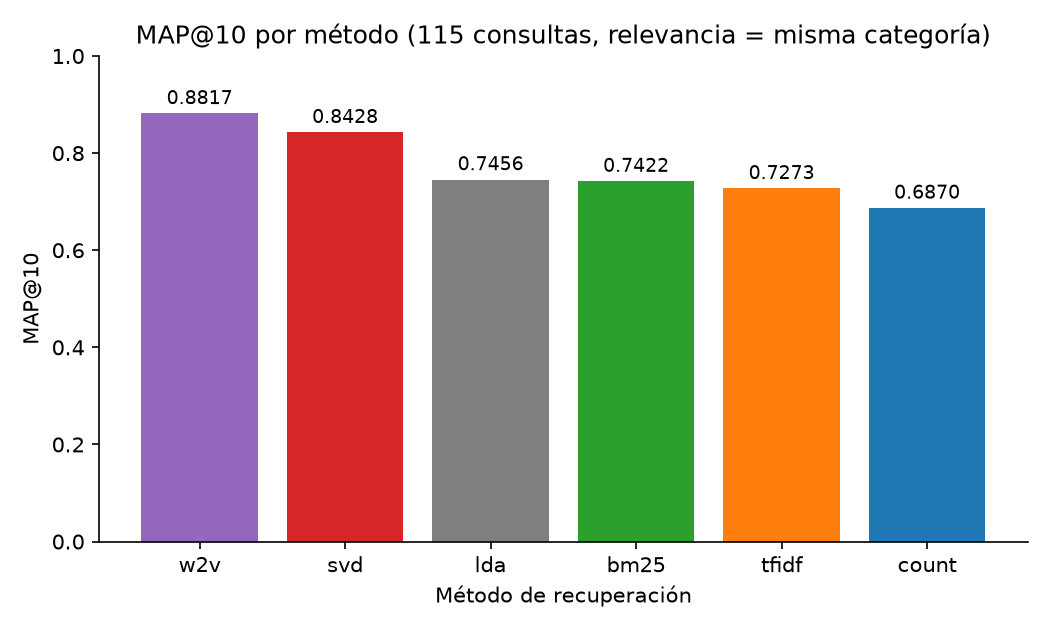

In [32]:
display(Image('reports/figuras/eval_map_por_metodo.png', width=700))

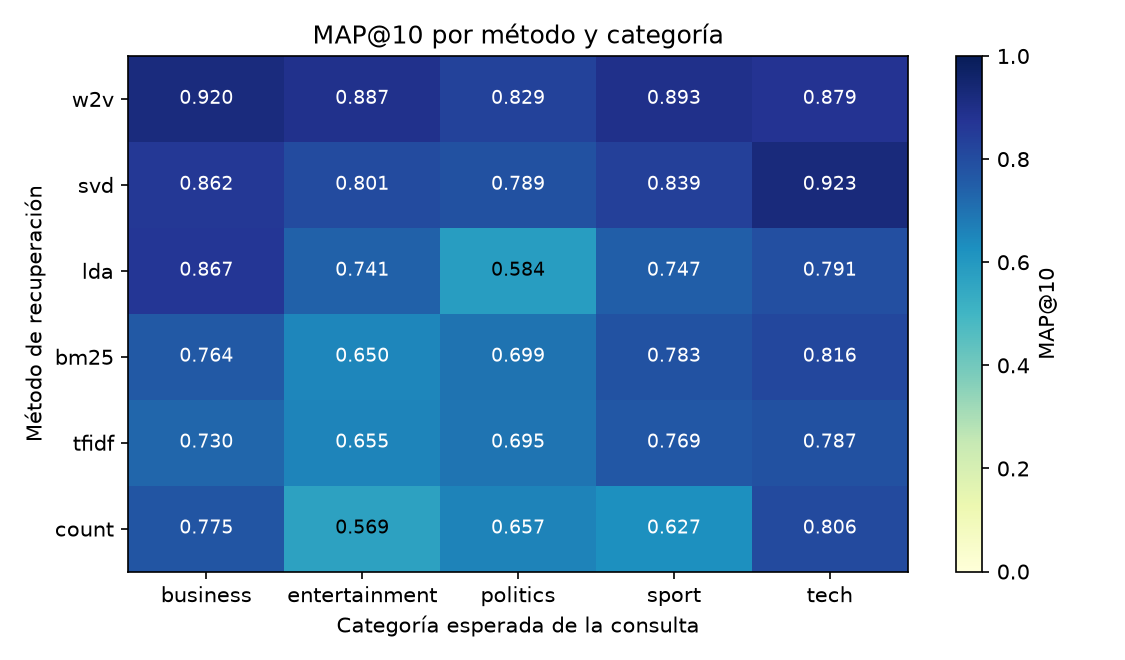

In [33]:
display(Image('reports/figuras/eval_heatmap_categoria.png', width=700))

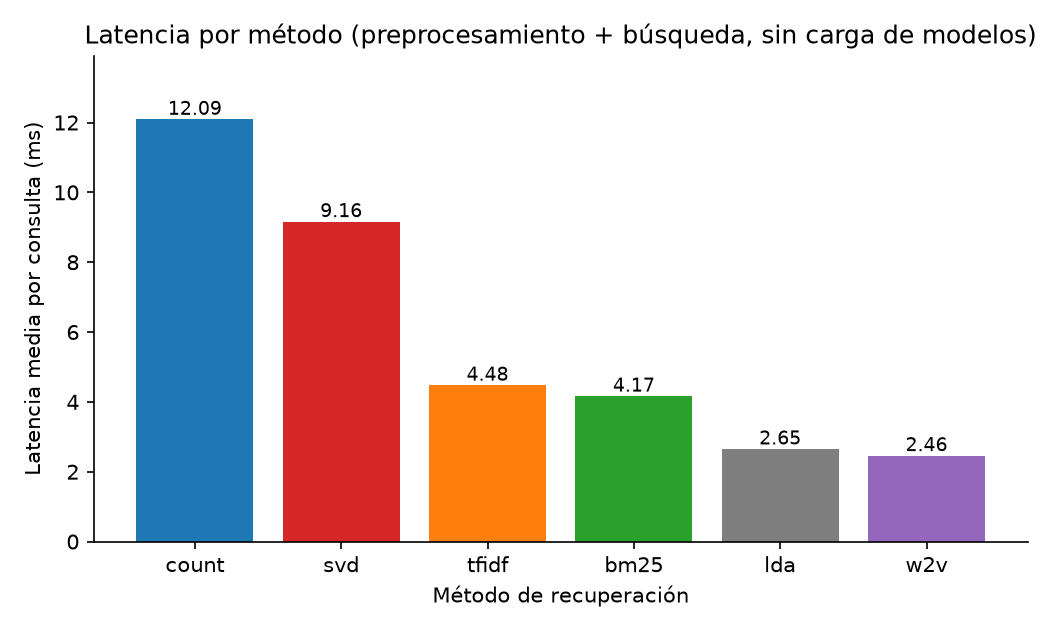

In [34]:
display(Image('reports/figuras/eval_latencia.png', width=700))

In [35]:
# Hallazgos del reporte de evaluación
texto_eval = open('reports/evaluacion.md', encoding='utf-8').read()
display(Markdown('### Hallazgos' + texto_eval.split('## Hallazgos')[1].split('\n## ')[0]))

### Hallazgos

1. **Word2Vec lidera con 88.17% de MAP@10; SVD le sigue con 84.28% y los métodos léxicos quedan atrás.**
   *Apoyo: la ventaja de Word2Vec sobre SVD (+3.89 puntos, IC 95% [-0.38, 8.22]) no es concluyente con 115 consultas; SVD supera a BM25 (74.22%) por +10.06 puntos, IC [6.62, 13.57]. Word2Vec es además el más rápido (2.46 ms por consulta).*

2. **BM25 (74.22%) y TF-IDF (72.73%) rinden casi igual; solo BM25 supera con claridad al conteo (68.70%).**
   *Apoyo: BM25 frente a TF-IDF, +1.49 puntos, IC [-0.15, 3.21]; BM25 frente a conteo, +5.52 puntos, IC [1.47, 9.71]; TF-IDF frente a conteo, +4.03 puntos, IC [-0.35, 8.15] (incluye 0).*

3. **Con consultas manuales cortas casi todos aciertan; con titulares de 8 palabras Word2Vec logra 86.39% y conteo 64.96%.**
   *Apoyo: en las 15 consultas manuales SVD y Word2Vec alcanzan 100.00% de MAP@10 y el peor, conteo, 93.64%.*


El reporte completo, con los dos casos donde los métodos discrepan y los intervalos de confianza, está en `reports/evaluacion.md`.

## 7. Presentación

La presentación ejecutiva se genera con `python-pptx` desde `src/presentacion/` con un sistema de diseño propio (`presentacion/estilo.json`), a partir del guion `presentacion/guion.md` y de `presentacion/slides.json`. El archivo final es `presentacion/salida/presentacion_final.pptx`.

Para regenerarla, desde la raíz: `python src/presentacion/diseno.py`, `graficas.py`, `generar.py` y `revisar.py`, en ese orden.

In [36]:
from pptx import Presentation

prs = Presentation('presentacion/salida/presentacion_final.pptx')
guion = json.load(open('presentacion/slides.json', encoding='utf-8'))
filas = []
for i, (slide, datos) in enumerate(zip(prs.slides, guion), start=1):
    texto = ' '.join(sh.text_frame.text for sh in slide.shapes if sh.has_text_frame)
    filas.append({'n': i, 'layout': datos['layout'], 'titulo': datos.get('titulo') or datos.get('frase') or datos.get('conclusion', ''), 'palabras': len(texto.split()),
                  'palabras_notas': len(slide.notes_slide.notes_text_frame.text.split())})
diapositivas = pd.DataFrame(filas).set_index('n')
assert diapositivas['palabras'].max() <= 60
diapositivas

,layout,titulo,palabras,palabras_notas
n,,,,
1,portada,Recuperación de información en BBC News,31,61
2,cifra_grande,"Encontrar la noticia correcta entre 2,225 exige un buscador, no paciencia",35,61
3,grafica,"Deporte y negocios suman 45.89% de las 2,225 noticias",26,60
4,cifra_grande,"99 noticias estaban duplicadas y quedaron 2,126 documentos únicos",31,56
5,grafica,Pocas palabras dominan el corpus: la frecuencia cae con exponente s = 0.6088,39,62
6,grafica,El vocabulario no deja de crecer: β = 0.5387,28,62
7,bloques,Cada categoría tiene su propia huella de palabras,44,61
8,flujo,La consulta se convierte en vector y se compara con cada documento,48,64
9,bloques,Cuatro maneras de convertir texto en números,53,55


In [37]:
estilo = json.load(open('presentacion/estilo.json', encoding='utf-8'))
revision = json.load(open('presentacion/salida/revision_automatica.json', encoding='utf-8'))
print('Paleta:', estilo['paleta'])
print(f"Revisión automática: {revision['errores']} errores, {revision['avisos']} avisos")

Paleta: {'fondo': '#F6F4EF', 'fondo_oscuro': '#14213D', 'tinta': '#1B1F24', 'tinta_suave': '#5C6370', 'acento': '#E07A1F', 'acento_2': '#2A9D8F', 'neutro': '#C9CCD1', 'acento_texto': '#B05400', 'superficie': '#FFFFFF', 'acento_suave': '#FBE9D7'}
Revisión automática: 0 errores, 0 avisos


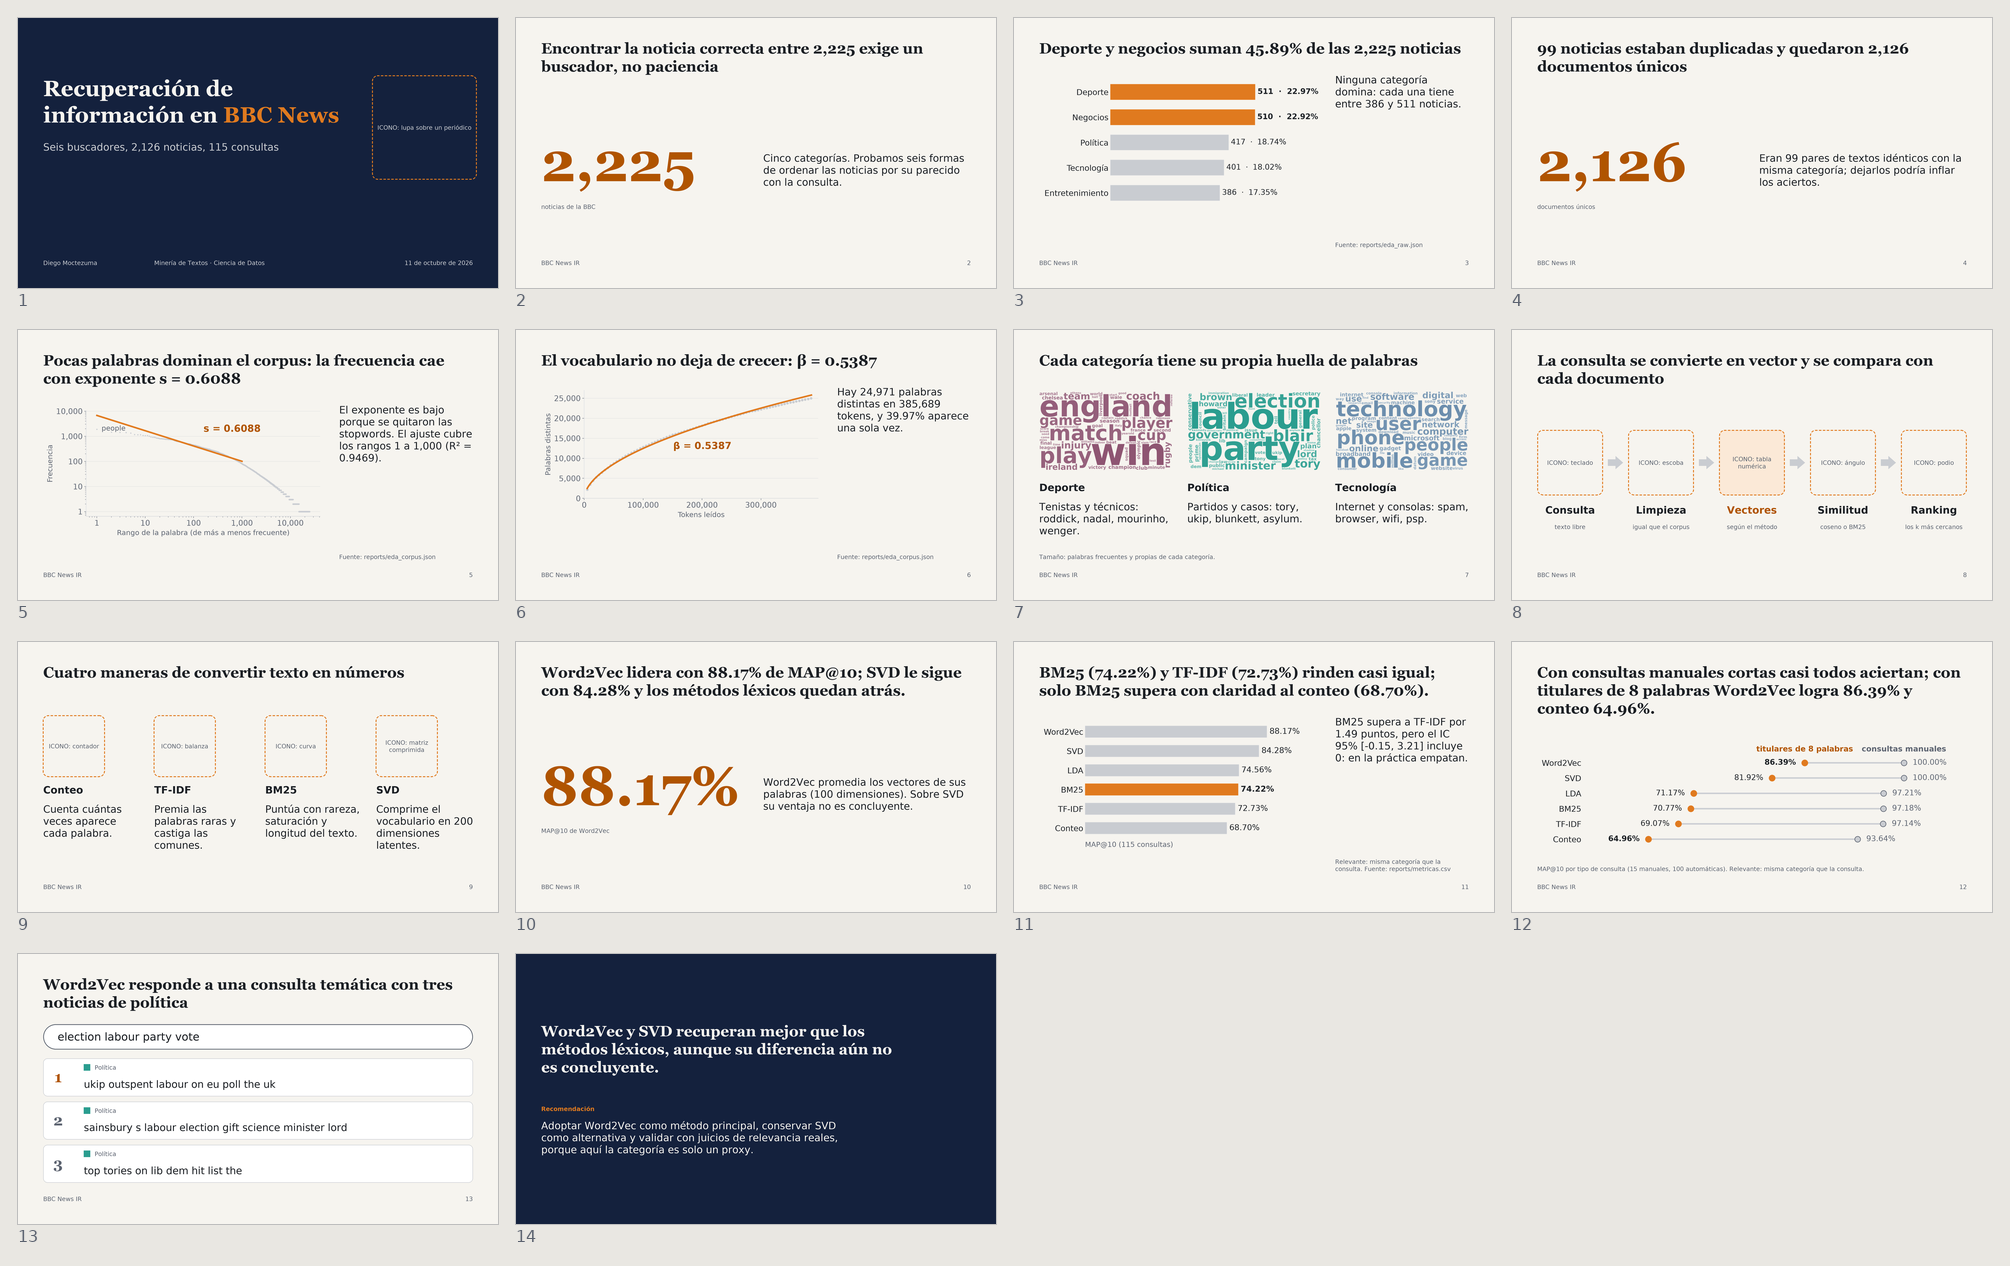

In [38]:
# Vista previa aproximada de las 14 diapositivas (dibujada con Pillow; revisar el .pptx en PowerPoint o Keynote antes de presentar)
display(Image('presentacion/salida/preview/contact_sheet.png', width=1000))

Los marcadores `ICONO: ...` de las diapositivas 1, 8 y 9 son espacios reservados para que el equipo coloque los iconos definitivos. La lista completa está en `presentacion/salida/revision_visual.md`.

## Estado final del pipeline

In [39]:
progreso = json.load(open('estado/progreso.json'))
pd.DataFrame(progreso['etapas']).T[['estado', 'intentos', 'commit', 'fecha']]

,estado,intentos,commit,fecha
setup,PASS,0,679174d,2026-10-11T16:35:34-0600
descarga,PASS,0,32ea3e5,2026-10-11T16:38:35-0600
eda_raw,PASS,0,6eb45bf,2026-10-11T16:42:51-0600
limpieza,PASS,0,59db66d,2026-10-11T16:50:37-0600
eda_corpus,PASS,0,d800aff,2026-10-11T16:56:13-0600
indices,PASS,0,d47162a,2026-10-11T17:16:43-0600
evaluacion,PASS,0,c5638bf,2026-10-11T17:25:44-0600
presentacion,PASS,0,da38933,2026-10-11T17:46:20-0600
